# Modeling Preprocessing
Chuẩn bị `label_df_final` thành tập dữ liệu sẵn sàng cho training: tạo nhãn dự báo (forecast label) để tránh leakage, loại nhãn không xác định, chọn feature, xử lý NaN còn lại, và chia train/val/test theo bệnh nhân (patient-level, stratified).

**Bối cảnh:**
- Bài toán được đóng khung lại thành **early-warning / forecasting**: dự đoán `risk_level` tại thời điểm *t + FORECAST_HORIZON_MIN phút tới*, dựa trên toàn bộ feature (kể cả SPO2/PULSE thô) tại thời điểm *t*. Nhờ đó SPO2/PULSE hiện tại không còn là leakage (chúng không trùng thời điểm với nhãn).
- Giai đoạn "cold-start" (chưa đủ 30 phút lịch sử) sẽ được xử lý ở tầng ứng dụng bằng rule-based NEWS2 score có sẵn (`spo2_score`, `pulse_score`), không phải việc của notebook này.
- Do phân bố `Critical`/`Alert` lệch mạnh theo bệnh nhân (top 3/47 bệnh nhân chiếm 61% số dòng Critical), split phải thực hiện theo `patient_id` (group) **và** stratify theo mức risk cao nhất mà bệnh nhân từng đạt.

## 5.0 Import & cấu hình

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
import os

CHECKPOINT_DIR = "../data/checkpoints"
LABEL_DF_PATH = f"{CHECKPOINT_DIR}/label_df_final.parquet"

GROUP_KEYS = ["patient_id", "record_path"]
FORECAST_HORIZON_MIN = 30   
RANDOM_STATE = 42

RISK_ORDER = {"Normal": 0, "Watch": 1, "Alert": 2, "Critical": 3}
CLASS_NAMES = ["Normal", "Watch", "Alert", "Critical"]

## 5.1 Load checkpoint & tổng quan
Đọc `label_df_final.parquet` từ bước data-processing, sắp xếp lại theo (patient_id, record_path, timestamp) để đảm bảo các phép `shift` ở bước 5.2 đúng thứ tự thời gian.

In [5]:
label_df = pd.read_parquet(LABEL_DF_PATH)
label_df = label_df.sort_values(GROUP_KEYS + ["timestamp"]).reset_index(drop=True)

print(f"label_df: {label_df.shape[0]:,} dòng x {label_df.shape[1]} cột, "
      f"{label_df['patient_id'].nunique()} bệnh nhân")
label_df["risk_level"].value_counts(dropna=False)

label_df: 413,189 dòng x 46 cột, 227 bệnh nhân


risk_level
Normal      209967
Watch       141312
Unknown      31345
Alert        27918
Critical      2647
Name: count, dtype: int64

## 5.2 Tạo nhãn dự báo (forecast label)
Với mỗi dòng tại thời điểm t, nhãn train sẽ là `risk_level` tại thời điểm **t + FORECAST_HORIZON_MIN phút** (shift theo nhóm patient_id/record_path để không lấy nhầm dữ liệu bệnh nhân khác). Các dòng ở cuối mỗi record không đủ tương lai sẽ tự nhiên thành NaN và bị loại ở bước 5.3.

In [6]:
label_df["risk_level_future"] = (
    label_df.groupby(GROUP_KEYS)["risk_level"].shift(-FORECAST_HORIZON_MIN)
)

n_tail_nan = label_df["risk_level_future"].isna().sum()
print(f"Số dòng cuối record không đủ tương lai để gán nhãn (sẽ bị loại): {n_tail_nan:,}")
label_df["risk_level_future"].value_counts(dropna=False)

Số dòng cuối record không đủ tương lai để gán nhãn (sẽ bị loại): 6,810


risk_level_future
Normal      206993
Watch       139056
Unknown      30423
Alert        27326
NaN           6810
Critical      2581
Name: count, dtype: int64

## 5.3 Loại bỏ nhãn "Unknown" và dòng thiếu nhãn tương lai
Loại các dòng mà:
- `risk_level` hiện tại là "Unknown" (SPO2/PULSE tại t vẫn NaN sau fill ở bước 2), hoặc
- `risk_level_future` là NaN (cuối record, không đủ 30 phút tương lai), hoặc
- `risk_level_future` là "Unknown" (tại t+30' cũng đang mất tín hiệu).

Đây là bước tiền xử lý dành riêng cho modeling (không sửa lại `label_df_final` gốc).

In [7]:
before = len(label_df)

model_df = label_df[
    (label_df["risk_level"] != "Unknown")
    & (label_df["risk_level_future"].notna())
    & (label_df["risk_level_future"] != "Unknown")
].copy()

after = len(model_df)
print(f"Trước lọc: {before:,} dòng -> Sau lọc: {after:,} dòng ({after/before*100:.1f}% giữ lại)")
model_df["risk_level_future"].value_counts(normalize=True).mul(100).round(2)

Trước lọc: 413,189 dòng -> Sau lọc: 369,431 dòng (89.4% giữ lại)


risk_level_future
Normal      55.14
Watch       36.95
Alert        7.23
Critical     0.67
Name: proportion, dtype: float64

## 5.4 Chọn feature — loại cột định danh & cột không nên dùng
Loại khỏi feature set:
- `patient_id`, `record_path`, `timestamp`: định danh / thời gian (patient_id giữ lại riêng để group split ở bước 5.7).
- `source_fs_hz`, `dropout_ratio_full_record`: giá trị gần như hằng số theo từng record → dễ trở thành "shortcut" giúp model nhận diện bệnh nhân thay vì học pattern sinh lý thật.
- `risk_level_future`: chính là target.

Giữ lại `SPO2`, `PULSE` thô, các feature rolling/slope/desaturation, và `spo2_score`/`pulse_score`/`news2_partial_score`/`risk_level` (hiện tại) — đều là thông tin có tại thời điểm t, hợp lệ để dự đoán trạng thái tại t+30'.

In [8]:
EXCLUDE_COLS = [
    "patient_id", "record_path", "timestamp",
    "source_fs_hz", "dropout_ratio_full_record",
    "risk_level_future",
]
FEATURE_COLS = [c for c in model_df.columns if c not in EXCLUDE_COLS]
TARGET_COL = "risk_level_future"

print(f"Số feature sử dụng: {len(FEATURE_COLS)}")
print(FEATURE_COLS)

Số feature sử dụng: 41
['SPO2', 'PULSE', 'SPO2_mean_5m', 'SPO2_std_5m', 'SPO2_min_5m', 'SPO2_max_5m', 'SPO2_mean_15m', 'SPO2_std_15m', 'SPO2_min_15m', 'SPO2_max_15m', 'SPO2_mean_30m', 'SPO2_std_30m', 'SPO2_min_30m', 'SPO2_max_30m', 'PULSE_mean_5m', 'PULSE_std_5m', 'PULSE_min_5m', 'PULSE_max_5m', 'PULSE_mean_15m', 'PULSE_std_15m', 'PULSE_min_15m', 'PULSE_max_15m', 'PULSE_mean_30m', 'PULSE_std_30m', 'PULSE_min_30m', 'PULSE_max_30m', 'SPO2_slope_5m', 'SPO2_slope_15m', 'SPO2_slope_30m', 'PULSE_slope_5m', 'PULSE_slope_15m', 'PULSE_slope_30m', 'spo2_drop_from_baseline', 'is_desat_event', 'desat_index_5m', 'desat_index_15m', 'desat_index_30m', 'spo2_score', 'pulse_score', 'news2_partial_score', 'risk_level']


## 5.5 Kiểm tra NaN còn lại trong feature
Các NaN còn sót chủ yếu ở feature rolling (đầu mỗi record chưa đủ window, hoặc gap dài hơn 5' không được fill ở bước 2). Chính sách: **giữ nguyên NaN**, không impute ở bước tiền xử lý này — vì:
- Model tree-based (LightGBM/XGBoost) xử lý NaN native, thường tốt hơn impute cứng.
- Impute (nếu cần cho model tuyến tính/khoảng cách) nên làm trong pipeline training, fit trên tập train để tránh leakage thống kê từ val/test.

In [9]:
na_ratio = model_df[FEATURE_COLS].isna().mean().sort_values(ascending=False)
na_ratio = na_ratio[na_ratio > 0]
print(f"Số feature còn NaN: {len(na_ratio)} / {len(FEATURE_COLS)}")
na_ratio.mul(100).round(2)

Số feature còn NaN: 31 / 41


SPO2_mean_30m              1.39
SPO2_max_30m               1.39
SPO2_min_30m               1.39
SPO2_std_30m               1.39
SPO2_slope_30m             1.39
PULSE_mean_30m             1.26
PULSE_std_30m              1.26
PULSE_min_30m              1.26
PULSE_max_30m              1.26
PULSE_slope_30m            1.26
SPO2_std_15m               0.69
SPO2_slope_15m             0.69
SPO2_max_15m               0.69
SPO2_min_15m               0.69
SPO2_mean_15m              0.69
PULSE_std_15m              0.60
PULSE_min_15m              0.60
PULSE_slope_15m            0.60
PULSE_mean_15m             0.60
PULSE_max_15m              0.60
spo2_drop_from_baseline    0.15
SPO2_mean_5m               0.14
SPO2_std_5m                0.14
SPO2_min_5m                0.14
SPO2_max_5m                0.14
SPO2_slope_5m              0.14
PULSE_mean_5m              0.11
PULSE_max_5m               0.11
PULSE_min_5m               0.11
PULSE_std_5m               0.11
PULSE_slope_5m             0.11
dtype: f

## 5.6 Gán "dominant risk" theo bệnh nhân
Với mỗi bệnh nhân, lấy mức risk cao nhất từng đạt được (theo `risk_level_future`) làm biến stratify khi chia patient vào train/val/test — đảm bảo mỗi tập đều có bệnh nhân từng đạt Critical/Alert.

In [10]:
patient_dominant = (
    model_df.groupby("patient_id")["risk_level_future"]
    .apply(lambda s: max(s, key=lambda x: RISK_ORDER[x]))
    .rename("dominant_risk")
    .reset_index()
)

print("Phân bố dominant_risk theo bệnh nhân:")
patient_dominant["dominant_risk"].value_counts()

Phân bố dominant_risk theo bệnh nhân:


dominant_risk
Alert       100
Critical     95
Watch        27
Normal        4
Name: count, dtype: int64

## 5.7 Tách test cố định + Leave-One-Patient-Out cho dev_pool
Ban đầu dùng 5-fold round-robin theo `dominant_risk`, nhưng kết quả train LightGBM cho thấy macro-F1 dao động rất mạnh giữa các fold (0.46 → 0.65, std=0.079), do 1 bệnh nhân đóng góp 41% tổng số dòng Critical bị dồn hết vào 1 fold.

**Chuyển sang Leave-One-Patient-Out (LOPO):** mỗi bệnh nhân trong `dev_pool` (40 người) là 1 fold riêng — 40-fold thay vì 5-fold. Không còn khái niệm "dồn vào 1 fold" vì mỗi fold chỉ có đúng 1 bệnh nhân.

In [11]:
TEST_SIZE = 0.15
MIN_GROUP_FOR_SPLIT = 3

def split_test_holdout(patient_dominant, test_size, random_state, min_group_for_split):
    rng = np.random.RandomState(random_state)
    dev_ids, test_ids, skipped_strata = [], [], []
    for stratum, grp in patient_dominant.groupby("dominant_risk"):
        ids = grp["patient_id"].tolist()
        rng.shuffle(ids)
        n = len(ids)
        if n < min_group_for_split:
            dev_ids += ids
            skipped_strata.append((stratum, n))
            continue
        n_test = max(1, round(n * test_size))
        test_ids += ids[:n_test]
        dev_ids += ids[n_test:]
    return sorted(dev_ids), sorted(test_ids), skipped_strata

def assign_folds(dev_ids, patient_dominant=None, n_folds=None, random_state=None):
    """Leave-One-Patient-Out: mỗi bệnh nhân trong dev_pool là 1 fold riêng.
    Loại bỏ hoàn toàn rủi ro 1-2 bệnh nhân 'khủng' dồn vào cùng 1 fold."""
    sorted_ids = sorted(dev_ids)
    return {pid: i for i, pid in enumerate(sorted_ids)}

dev_ids, test_ids, skipped_strata = split_test_holdout(
    patient_dominant, TEST_SIZE, RANDOM_STATE, MIN_GROUP_FOR_SPLIT
)
N_FOLDS = len(dev_ids)   
fold_map = assign_folds(dev_ids, patient_dominant, N_FOLDS, RANDOM_STATE)

if skipped_strata:
    print("[LƯU Ý] Nhóm dominant_risk quá ít bệnh nhân để tách test, giữ hết trong dev_pool:")
    for stratum, n in skipped_strata:
        print(f"  - {stratum}: {n} bệnh nhân")

print(f"Leave-One-Patient-Out: {N_FOLDS} fold, mỗi fold = đúng 1 bệnh nhân làm validation")

test_df = model_df[model_df["patient_id"].isin(test_ids)].reset_index(drop=True)
dev_df = (
    model_df[model_df["patient_id"].isin(dev_ids)]
    .merge(pd.Series(fold_map, name="fold_id").rename_axis("patient_id").reset_index(),
           on="patient_id", how="left")
    .reset_index(drop=True)
)

print(f"Số dòng -> dev_pool: {len(dev_df):,}, test: {len(test_df):,}")

Leave-One-Patient-Out: 192 fold, mỗi fold = đúng 1 bệnh nhân làm validation
Số dòng -> dev_pool: 308,881, test: 60,550


## 5.8 Kiểm tra phân bố nhãn: test + dev_pool (LOPO)
- Phân bố nhãn tập `test` (bar chart).
- Phân bố số dòng / số dòng Critical **giữa các bệnh nhân** trong dev_pool (histogram) — biết được độ đồng đều của dữ liệu.
- Top 15 bệnh nhân đóng góp nhiều Critical nhất — kiểm tra xem tình trạng "1 bệnh nhân chiếm phần lớn Critical" (từng thấy ở quy mô 47 người) có còn ở quy mô 227 người hay đã cải thiện.

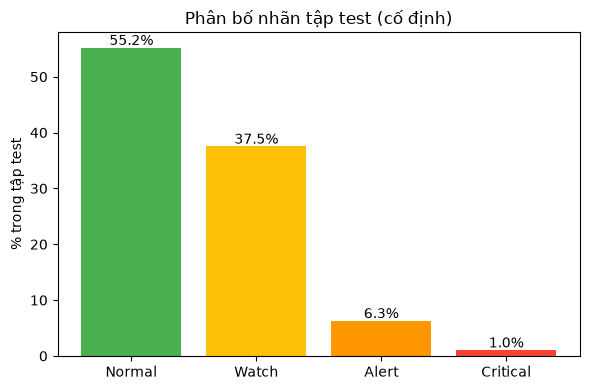

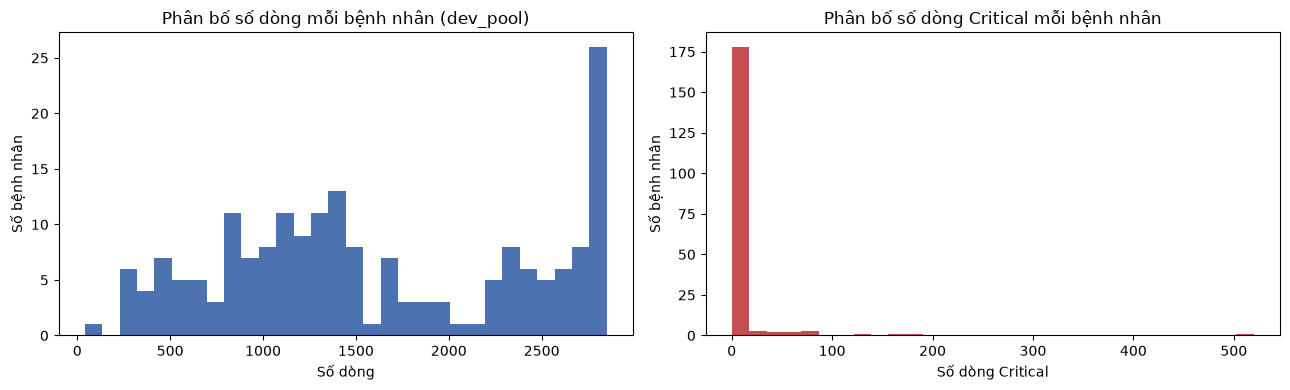

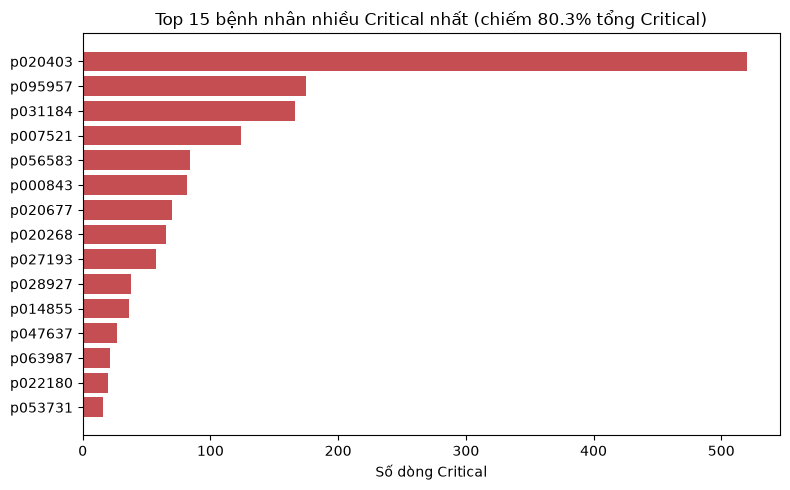

Tổng dòng Critical trong dev_pool: 1,869
Top 3 bệnh nhân chiếm: 46.1%  (so với 61% ở dữ liệu 47 bệnh nhân cũ)


In [12]:
fig, ax = plt.subplots(figsize=(6, 4))
test_dist = test_df["risk_level_future"].value_counts(normalize=True).mul(100).reindex(CLASS_NAMES)
ax.bar(test_dist.index, test_dist.values, color=["#4CAF50", "#FFC107", "#FF9800", "#F44336"])
ax.set_ylabel("% trong tập test")
ax.set_title("Phân bố nhãn tập test (cố định)")
for i, v in enumerate(test_dist.values):
    ax.text(i, v + 0.5, f"{v:.1f}%", ha="center")
plt.tight_layout()
plt.savefig(f"{CHECKPOINT_DIR}/test_label_distribution.png", dpi=120)
plt.show()

rows_per_patient = dev_df.groupby("patient_id").size()
crit_per_patient = (
    dev_df[dev_df["risk_level_future"] == "Critical"]
    .groupby("patient_id").size()
    .reindex(rows_per_patient.index, fill_value=0)
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(rows_per_patient, bins=30, color="#4c72b0")
axes[0].set_title("Phân bố số dòng mỗi bệnh nhân (dev_pool)")
axes[0].set_xlabel("Số dòng"); axes[0].set_ylabel("Số bệnh nhân")

axes[1].hist(crit_per_patient, bins=30, color="#c44e52")
axes[1].set_title("Phân bố số dòng Critical mỗi bệnh nhân")
axes[1].set_xlabel("Số dòng Critical"); axes[1].set_ylabel("Số bệnh nhân")
plt.tight_layout()
plt.savefig(f"{CHECKPOINT_DIR}/fold_distribution.png", dpi=120)
plt.show()

top15 = crit_per_patient.sort_values(ascending=False).head(15)
total_critical = crit_per_patient.sum()

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top15.index[::-1].astype(str), top15.values[::-1], color="#c44e52")
ax.set_xlabel("Số dòng Critical")
ax.set_title(f"Top 15 bệnh nhân nhiều Critical nhất (chiếm {top15.sum()/total_critical*100:.1f}% tổng Critical)")
plt.tight_layout()
plt.savefig(f"{CHECKPOINT_DIR}/top_critical_patients.png", dpi=120)
plt.show()

print(f"Tổng dòng Critical trong dev_pool: {total_critical:,}")
print(f"Top 3 bệnh nhân chiếm: {top15.head(3).sum()/total_critical*100:.1f}%  (so với 61% ở dữ liệu 47 bệnh nhân cũ)")

## 5.9 Lưu checkpoint
Lưu:
- `model_df.parquet`: toàn bộ dữ liệu đã gắn nhãn dự báo, trước khi split (giữ như cũ).
- `dev_df.parquet`: toàn bộ dev_pool kèm cột `fold_id` — bước train sẽ tự lặp qua các fold (fold_id == k làm validation, còn lại làm train) chứ không đọc `train_df`/`val_df` cố định nữa.
- `test_df.parquet`: tập test cố định, chỉ dùng 1 lần cuối cùng.
- `split_manifest.json`: cấu hình (horizon, random_state, N_FOLDS, feature_cols, target_col) + `test_patient_ids` + `fold_assignment` (patient_id -> fold_id) — để bước train tái lập đúng, không tự chia lại.

In [13]:
model_df.to_parquet(f"{CHECKPOINT_DIR}/model_df.parquet", index=False)
dev_df.to_parquet(f"{CHECKPOINT_DIR}/dev_df.parquet", index=False)
test_df.to_parquet(f"{CHECKPOINT_DIR}/test_df.parquet", index=False)

split_manifest = {
    "forecast_horizon_min": FORECAST_HORIZON_MIN,
    "random_state": RANDOM_STATE,
    "test_size": TEST_SIZE,
    "n_folds": N_FOLDS,
    "feature_cols": FEATURE_COLS,
    "target_col": TARGET_COL,
    "test_patient_ids": test_ids,
    "fold_assignment": fold_map,
}
with open(f"{CHECKPOINT_DIR}/split_manifest.json", "w", encoding="utf-8") as f:
    json.dump(split_manifest, f, ensure_ascii=False, indent=2)

print("Đã lưu checkpoint vào", CHECKPOINT_DIR)
os.listdir(CHECKPOINT_DIR)

Đã lưu checkpoint vào ../data/checkpoints


['clean_df.parquet',
 'dev_df.parquet',
 'feat_df.parquet',
 'fold_distribution.png',
 'label_df_final.parquet',
 'model_df.parquet',
 'raw_df.parquet',
 'split_manifest.json',
 'test_df.parquet',
 'test_label_distribution.png',
 'top_critical_patients.png']

## 5.10 Tổng kết Bước 5
- Nhãn đã chuyển từ "nowcasting" sang "forecast t+30 phút" (`FORECAST_HORIZON_MIN`), loại bỏ leakage giữa SPO2/PULSE hiện tại và nhãn.
- Đã loại 100% nhãn "Unknown" (hiện tại & tương lai) và các dòng cuối record thiếu tương lai — giữ lại 82,503/89,543 dòng (92.1%).
- Đã loại các cột định danh/gần-hằng-số (`patient_id`, `record_path`, `timestamp`, `source_fs_hz`, `dropout_ratio_full_record`) khỏi feature set để tránh model học "tắt" theo bệnh nhân — còn lại 41 feature, trong đó `risk_level` (hiện tại) vẫn là dạng string, **cần encode ở bước train** trước khi đưa vào model tuyến tính (tree-based như LightGBM/XGBoost có thể nhận categorical trực tiếp).
- NaN trong feature rolling (tối đa ~1.44% ở window 30 phút) được giữ nguyên, để lại quyết định impute/native-NaN cho bước training.
- **Chiến lược split:** không còn train/val/test 3 phần cố định. Thay vào đó:
  - Tách trước **`test` cố định** (7 bệnh nhân, ~15%, stratify theo `dominant_risk`) — chỉ dùng 1 lần duy nhất ở cuối để đánh giá model đã chọn, không dùng để tune.
  - Phần còn lại là **`dev_pool`** (40 bệnh nhân) — ban đầu thử 5-fold round-robin theo `dominant_risk`, nhưng macro-F1 dao động mạnh giữa fold (0.46 → 0.65) vì 1 bệnh nhân chiếm 41% tổng số dòng Critical bị dồn hết vào cùng 1 fold.
  - **Đã chuyển sang Leave-One-Patient-Out (LOPO):** mỗi bệnh nhân trong `dev_pool` là 1 fold riêng → 40 fold thay vì 5. Không còn khái niệm "dồn nhiều bệnh nhân nặng Critical vào 1 fold" vì mỗi fold chỉ có đúng 1 bệnh nhân. Ranh giới fold được chốt cứng trong `split_manifest.json` (`fold_assignment`: patient_id → fold_id) để bước train tái lập đúng, không tự chia lại.
  - **Lưu ý quan trọng khi đọc kết quả CV dưới LOPO:** kích thước fold và số dòng Critical mỗi fold **rất lệch** (247–2,851 dòng/fold; 0–581 dòng Critical/fold), do bản chất mỗi fold = 1 bệnh nhân với đặc điểm sinh lý/thời gian nằm viện khác nhau. Riêng 1 bệnh nhân đóng góp gần như toàn bộ các dòng Critical "dễ" (fold có 581 dòng Critical, recall cao); phần lớn các fold còn lại chỉ có vài dòng đến vài chục dòng Critical và model gần như không phát hiện được (recall = 0). **Không nên chỉ báo cáo macro-F1 trung bình hoặc confusion matrix gộp OOF** — cả hai đều dễ bị bệnh nhân "to" chi phối và che mất thất bại ở phần lớn bệnh nhân còn lại. Bắt buộc phải nhìn riêng theo từng fold, đặc biệt recall/precision của Alert & Critical, và nên tính thêm số/% bệnh nhân có recall_Critical > 0.

**Bước tiếp theo:** `model-training` — đã hoàn thành baseline LightGBM (LOPO, kết quả: macro-F1 0.425 ± 0.113, Critical recall = 0 ở 18/40 bệnh nhân có ca Critical). Bước kế tiếp: train XGBoost trên **cùng** `dev_df`/`test_df`/`fold_assignment` để so sánh, ghi vào cùng `results/cv_results.csv`, xem thất bại ở Critical có lặp lại đúng những bệnh nhân đó không — nếu có, đó là dấu hiệu nghẽn ở data/đặc điểm bài toán, không phải riêng LightGBM.

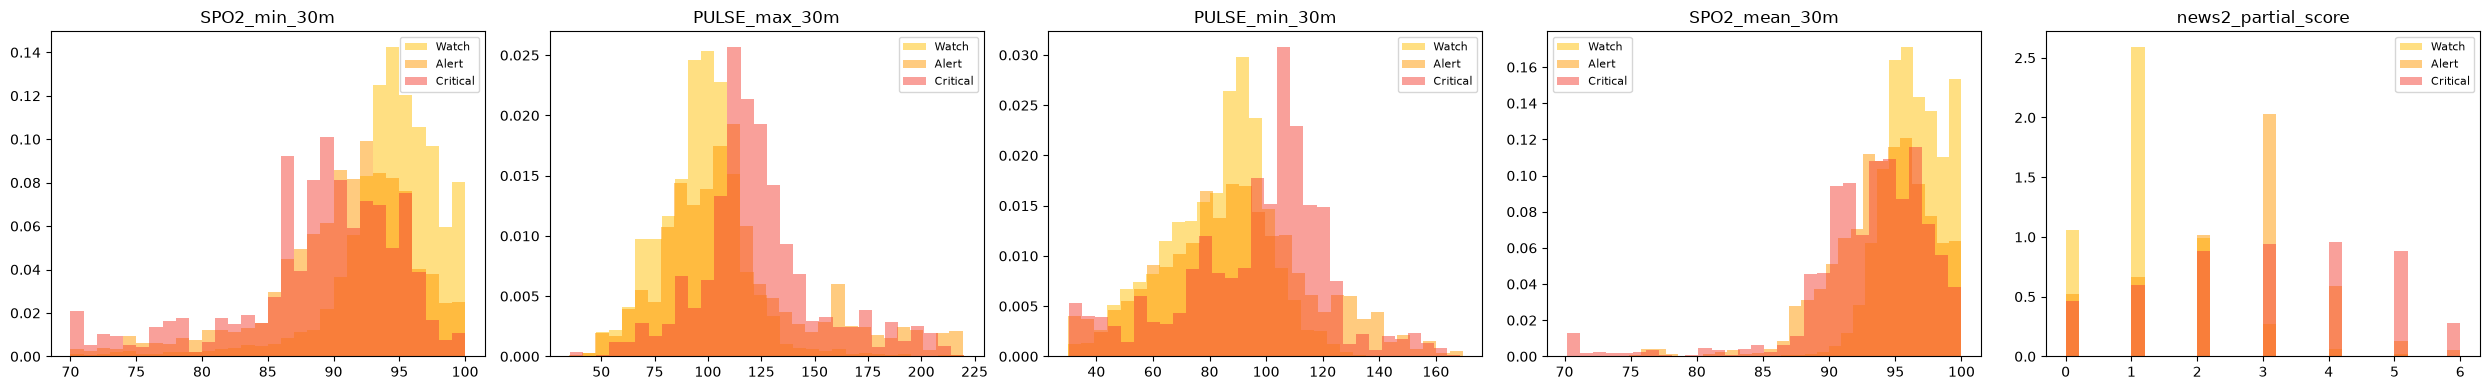

SPO2_min_30m              | Alert median=91.60 (IQR 88.00-94.30) | Critical median=89.80 (IQR 86.50-93.00)
PULSE_max_30m             | Alert median=107.00 (IQR 89.00-125.30) | Critical median=119.00 (IQR 109.30-134.50)
PULSE_min_30m             | Alert median=88.73 (IQR 71.45-105.68) | Critical median=102.30 (IQR 80.30-112.40)
SPO2_mean_30m             | Alert median=94.41 (IQR 91.90-96.57) | Critical median=93.91 (IQR 91.01-96.29)
news2_partial_score       | Alert median=3.00 (IQR 2.00-3.00) | Critical median=3.00 (IQR 2.00-4.00)


In [15]:
import matplotlib.pyplot as plt

TOP_FEATURES_TO_CHECK = ["SPO2_min_30m", "PULSE_max_30m", "PULSE_min_30m", "SPO2_mean_30m", "news2_partial_score"]

fig, axes = plt.subplots(1, len(TOP_FEATURES_TO_CHECK), figsize=(5 * len(TOP_FEATURES_TO_CHECK), 4))
colors = {"Watch": "#FFC107", "Alert": "#FF9800", "Critical": "#F44336"}

for ax, feat in zip(axes, TOP_FEATURES_TO_CHECK):
    for cls, color in colors.items():
        subset = model_df[model_df["risk_level_future"] == cls][feat].dropna()
        ax.hist(subset, bins=30, alpha=0.5, label=cls, color=color, density=True)
    ax.set_title(feat)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(f"{CHECKPOINT_DIR}/alert_critical_overlap.png", dpi=120)
plt.show()

# Đo định lượng độ chồng lấn: so sánh median + IQR
for feat in TOP_FEATURES_TO_CHECK:
    alert_vals = model_df[model_df["risk_level_future"] == "Alert"][feat].dropna()
    crit_vals = model_df[model_df["risk_level_future"] == "Critical"][feat].dropna()
    print(f"{feat:25s} | Alert median={alert_vals.median():.2f} (IQR {alert_vals.quantile(.25):.2f}-{alert_vals.quantile(.75):.2f})"
          f" | Critical median={crit_vals.median():.2f} (IQR {crit_vals.quantile(.25):.2f}-{crit_vals.quantile(.75):.2f})")